In [1]:
!nvidia-smi

Mon Oct 26 08:50:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

import torch

print("PyTorch 版本：", torch.__version__)
print("GPU 是否可用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 型號：", torch.cuda.get_device_name(0))


PyTorch 版本： 2.11.0+cu130
GPU 是否可用： True
GPU 型號： Tesla T4


In [4]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [5]:

import os

project_dir = "/content/drive/MyDrive/AI專題"
os.makedirs(project_dir, exist_ok=True)

print("專案資料夾：", project_dir)


專案資料夾： /content/drive/MyDrive/AI專題


In [1]:
!pip install -q ultralytics

In [2]:
from ultralytics import YOLO
import torch

print("PyTorch 版本：", torch.__version__)
print("GPU 可用：", torch.cuda.is_available())

model = YOLO("yolo26n.pt")

print("YOLO 模型載入完成！")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch 版本： 2.11.0+cu130
GPU 可用： True
YOLO 模型載入完成！


In [3]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    save=True
)

print("辨識完成！")


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 9.6ms
Speed: 94.8ms preprocess, 9.6ms inference, 34.2ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
辨識完成！


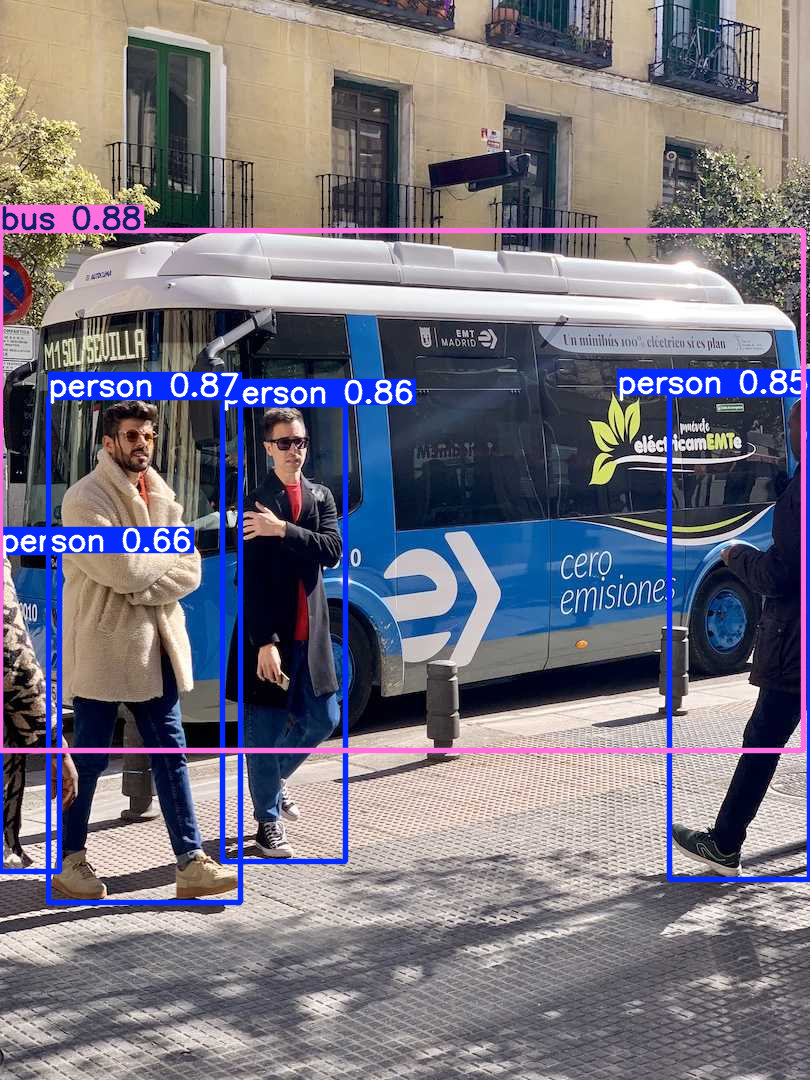

In [4]:
from IPython.display import display
from PIL import Image

result_image = results[0].plot()
display(Image.fromarray(result_image[:, :, ::-1]))

In [5]:

from ultralytics import YOLO

# 載入預訓練模型
model = YOLO("yolo26n.pt")

# 使用 COCO8 資料集訓練 3 個回合
train_results = model.train(
    data="coco8.yaml",
    epochs=3,
    imgsz=640,
    batch=8,
    project="/content/yolo_project",
    name="first_train",
    exist_ok=True
)

print("訓練完成！")


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=first_train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap

In [6]:

import os

result_dir = "/content/yolo_project/first_train"

print("訓練結果資料夾內容：")
for filename in os.listdir(result_dir):
    print(filename)


訓練結果資料夾內容：
results.csv
BoxP_curve.png
BoxF1_curve.png
args.yaml
confusion_matrix.png
train_batch0.jpg
labels.jpg
train_batch1.jpg
train_batch2.jpg
confusion_matrix_normalized.png
results.png
val_batch0_labels.jpg
BoxPR_curve.png
val_batch0_pred.jpg
weights
BoxR_curve.png


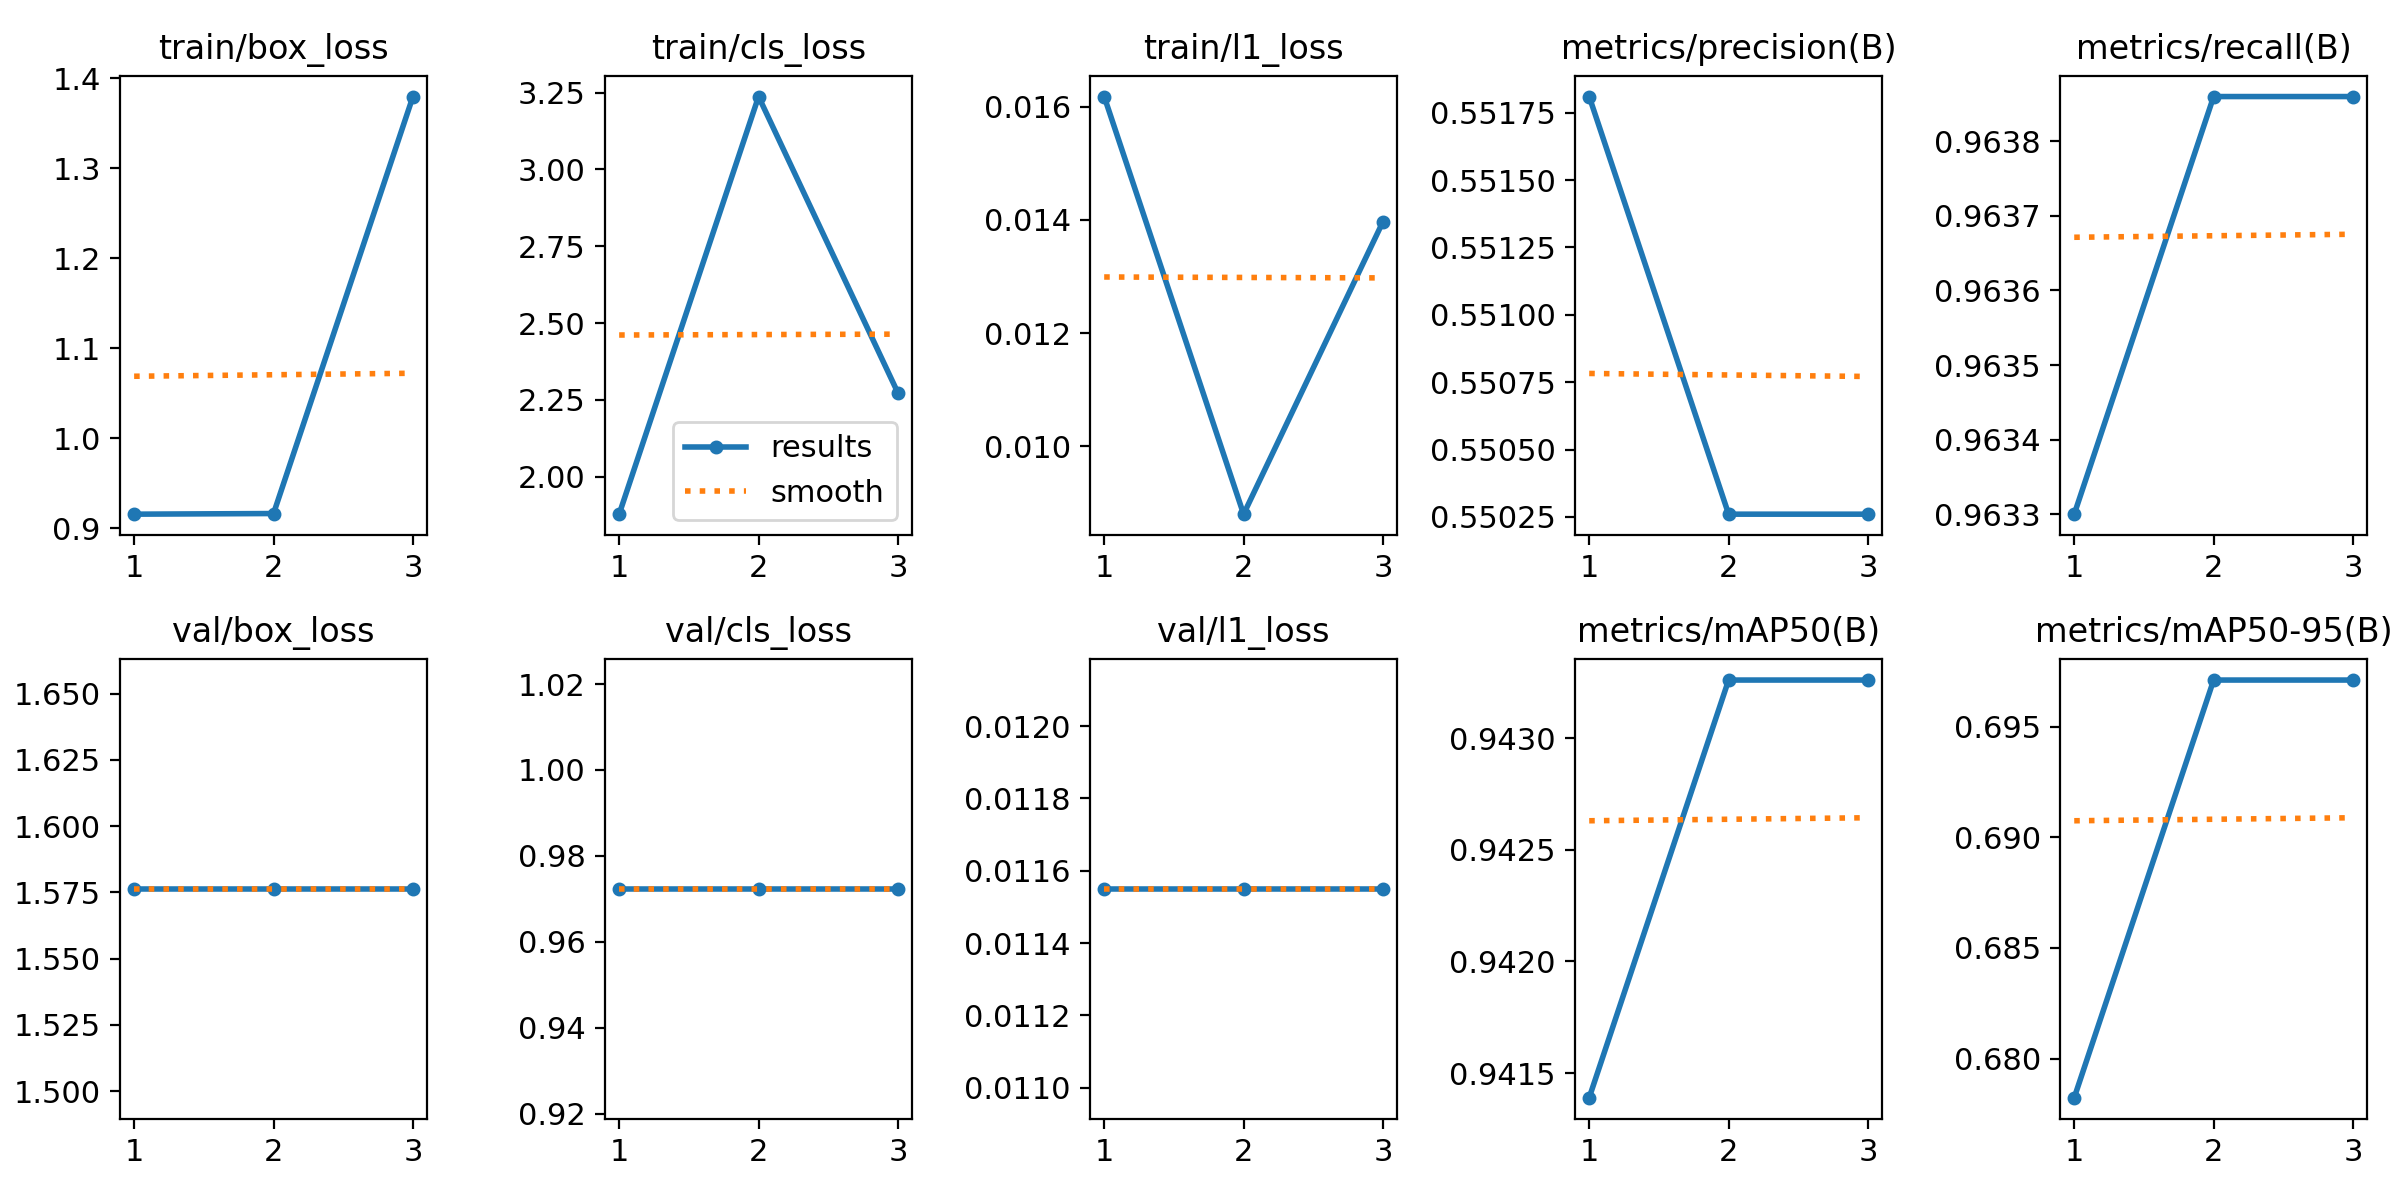

In [7]:

from IPython.display import display, Image
import os

chart_path = "/content/yolo_project/first_train/results.png"

if os.path.exists(chart_path):
    display(Image(filename=chart_path))
else:
    print("找不到圖表，請確認訓練是否成功完成。")



Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 8.8ms
Speed: 1.8ms preprocess, 8.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


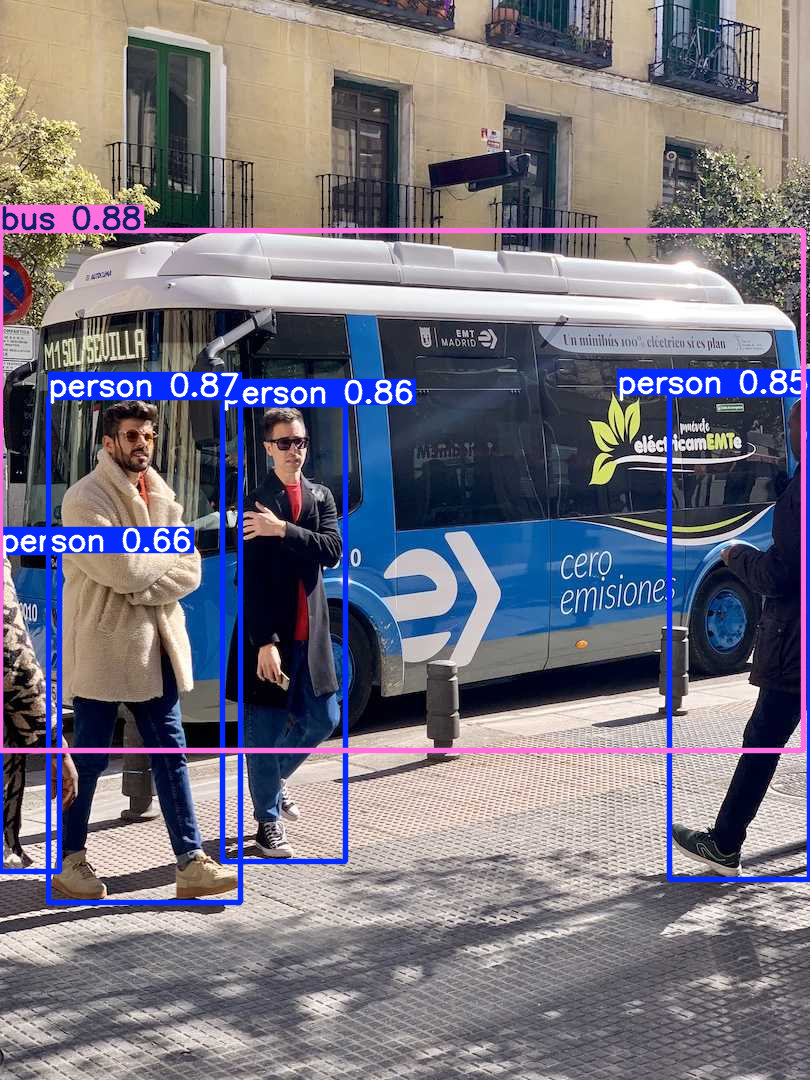

In [8]:

from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import os

best_model_path = (
    "/content/yolo_project/first_train/weights/best.pt"
)

if os.path.exists(best_model_path):
    trained_model = YOLO(best_model_path)

    results = trained_model.predict(
        source="https://ultralytics.com/images/bus.jpg",
        conf=0.25
    )

    display(
        Image.fromarray(
            results[0].plot()[:, :, ::-1]
        )
    )
else:
    print("找不到 best.pt，請先完成訓練。")


In [9]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

source_path = (
    "/content/yolo_project/first_train/weights/best.pt"
)

save_dir = "/content/drive/MyDrive/YOLO專題"
os.makedirs(save_dir, exist_ok=True)

if os.path.exists(source_path):
    shutil.copy2(
        source_path,
        os.path.join(save_dir, "best.pt")
    )
    print("模型已保存到 Google 雲端硬碟！")
else:
    print("找不到模型檔案，請先確認訓練是否完成。")


Mounted at /content/drive
模型已保存到 Google 雲端硬碟！
